In [166]:
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt
import pickle
from collections import Counter
from torch.utils.data import Dataset
import random
import matplotlib.pyplot as plt
from PIL import Image

In [151]:
ROOT_PATH = "data/faces_webface_112x112"

In [152]:
class PairDataset(Dataset):
    def __init__(self, dataset_path, images_are_bytes = False):
        dataset_path = ROOT_PATH + "/" + dataset_path
        with open(dataset_path, "rb") as f:
            data = pickle.load(f, encoding="bytes")
            self.images = data[0]
            self.labels = data[1]

        self.images_are_bytes = images_are_bytes

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image1_data = self.images[index * 2]
        image2_data = self.images[index * 2 + 1]

        if not self.images_are_bytes:
            image1_data = image1_data.tobytes()
            image2_data = image2_data.tobytes()

        image1 = Image.open(BytesIO(image1_data)).convert("RGB")
        image2 = Image.open(BytesIO(image2_data)).convert("RGB")

        label = self.labels[index]
        return image1, image2, label

In [153]:
class FaceDataset(Dataset):
    def __init__(self, dataset_path):
        dataset_path = ROOT_PATH + "/" + dataset_path
        with open(dataset_path, "rb") as f:
            data = pickle.load(f, encoding="bytes")        
            self.images = data[0]
            
    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = Image.open(BytesIO(self.images[index].tobytes())).convert("RGB")
        return image

In [154]:
def count_labels(labels):
    counts = Counter(labels)

    return {
        True: counts[True],
        False: counts[False],
    }

In [173]:
def show_image_pairs(
    pair_dataset,
    max_images=10,
    random_sample=True,
    true_indexes=None,
    false_indexes=None,
):
    if true_indexes is None or false_indexes is None:
        true_indices = [
            i for i, label in enumerate(pair_dataset.labels)
            if bool(label)
        ]
        false_indices = [
            i for i, label in enumerate(pair_dataset.labels)
            if not bool(label)
        ]

        if random_sample:
            true_indices = random.sample(
                true_indices, min(max_images, len(true_indices))
            )
            false_indices = random.sample(
                false_indices, min(max_images, len(false_indices))
            )
        else:
            true_indices = true_indices[:max_images]
            false_indices = false_indices[:max_images]
    else:
        true_indices = list(true_indexes)[:max_images]
        false_indices = list(false_indexes)[:max_images]

    selected_indices = true_indices + false_indices
    n_pairs = len(selected_indices)

    if n_pairs == 0:
        print("No image pairs found.")
        return

    pairs_per_row = 4
    n_cols = pairs_per_row * 2
    n_rows = (n_pairs + pairs_per_row - 1) // pairs_per_row

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 3 * n_rows),
        squeeze=False,
    )

    for idx, pair_idx in enumerate(selected_indices):
        row = idx // pairs_per_row
        col = (idx % pairs_per_row) * 2

        image1, image2, label = pair_dataset[pair_idx]

        axes[row, col].imshow(image1)
        axes[row, col].axis("off")

        axes[row, col + 1].imshow(image2)
        axes[row, col + 1].axis("off")

        pair_type = "TRUE (Same)" if idx < len(true_indices) else "FALSE (Different)"
        axes[row, col].set_title(
            f"Pair {pair_idx}\n{pair_type}", fontsize=9
        )

    for idx in range(n_pairs, n_rows * pairs_per_row):
        row = idx // pairs_per_row
        col = (idx % pairs_per_row) * 2
        axes[row, col].axis("off")
        axes[row, col + 1].axis("off")

    plt.tight_layout()
    plt.show()

### agedb_30

In [155]:
!ls data/faces_webface_112x112

agedb_30.bin  cfp_ff.bin  cplfw.bin  property  train.csv  train.lst
calfw.bin     cfp_fp.bin  lfw.bin    train     train.idx  train.rec


In [156]:
agedb30_dataset = PairDataset("agedb_30.bin")

In [157]:
len(agedb30_dataset), len(agedb30_dataset.images)

(6000, 12000)

In [228]:
image1, image2, label = agedb30_dataset[1020]

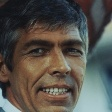

In [229]:
image1

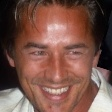

In [230]:
image2

In [231]:
label

False

In [162]:
count_labels(agedb30_dataset.labels)

{True: 3000, False: 3000}

In [163]:
agedb30_face_dataset = FaceDataset("agedb_30.bin")

In [164]:
image = agedb30_face_dataset[1]

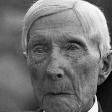

In [165]:
image

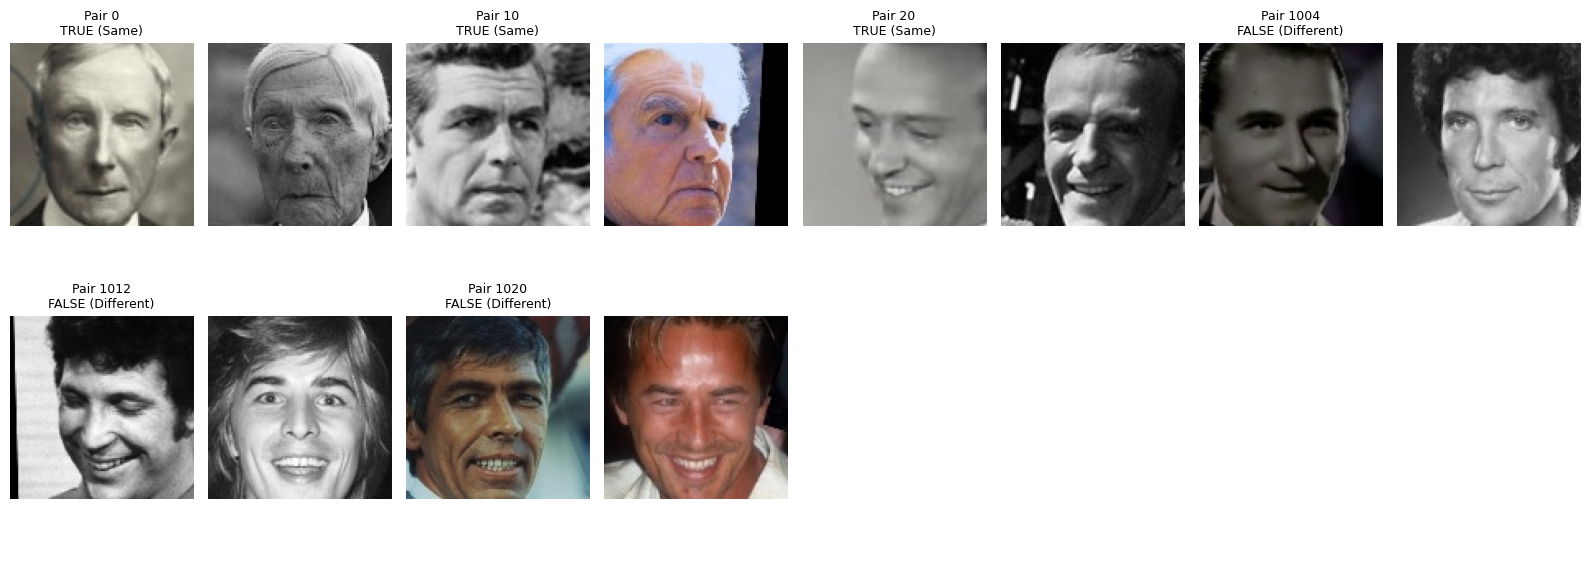

In [232]:
show_image_pairs(
    agedb30_dataset,
    true_indexes=[0, 10, 20],
    false_indexes=[1004, 1012, 1020],
)

### cfp_ff

In [112]:
cfp_ff_dataset = PairDataset("cfp_ff.bin")

In [113]:
count_labels(cfp_ff_dataset.labels)

{True: 3500, False: 3500}

In [114]:
image1, image2, label = cfp_ff_dataset[1500]

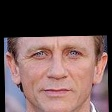

In [115]:
image1

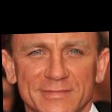

In [116]:
image2

In [117]:
label

True

In [118]:
image1.size

(112, 112)

### cfp_fp

In [119]:
cfp_fp_dataset = PairDataset("cfp_fp.bin")

In [120]:
count_labels(cfp_fp_dataset.labels)

{True: 3500, False: 3500}

In [121]:
image1, image2, label = cfp_fp_dataset[1500]

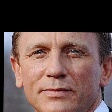

In [122]:
image1

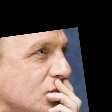

In [123]:
image2

In [124]:
label

True

### calfw

In [125]:
calfw_dataset = PairDataset("calfw.bin")

In [126]:
count_labels(calfw_dataset.labels)

{True: 3000, False: 3000}

In [127]:
image1, image2, label = calfw_dataset[0]

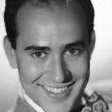

In [128]:
image1

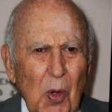

In [129]:
image2

In [130]:
label

1

### cplfw

In [131]:
cplfw_dataset = PairDataset("cplfw.bin")

In [132]:
count_labels(cplfw_dataset.labels)

{True: 3000, False: 3000}

In [133]:
image1, image2, label = cplfw_dataset[1300]

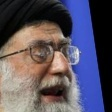

In [134]:
image1

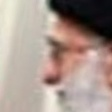

In [135]:
image2

In [136]:
label

1

### lfw

In [140]:
lfw_dataset = PairDataset("lfw.bin", images_are_bytes = True)

In [141]:
count_labels(lfw_dataset.labels)

{True: 3000, False: 3000}

In [146]:
image1, image2, label = lfw_dataset[0]

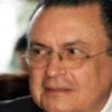

In [147]:
image1

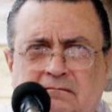

In [148]:
image2

In [149]:
label

True